In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12

# В Google Colab файлы лежат в текущей рабочей директории
data_dir = Path('.')

files = {
    'diffus': data_dir / 'L_diffus_eq.txt',
    'xmom':   data_dir / 'L_xmom_eq.txt',
    'ymom':   data_dir / 'L_ymom_eq.txt',
    'n':      data_dir / 'L_n.txt',
    'low_bc': data_dir / 'L_low_bc.txt',
}

labels = {
    'diffus': r'$L_{\mathrm{diffus}}$ (невязка диффузии)',
    'xmom':   r'$L_{x\mathrm{mom}}$ (невязка $O_x$)',
    'ymom':   r'$L_{y\mathrm{mom}}$ (невязка $O_y$)',
    'n':      r'$L_n$ (отклонение от данных)',
    'low_bc': r'$L_{\mathrm{bc}}$ (граничные условия)',
}

# Проверка наличия файлов
missing = [str(p) for p in files.values() if not p.exists()]
if missing:
    raise FileNotFoundError(
        'Не найдены файлы:\n' + '\n'.join(missing) +
        '\n\nЗагрузите их в Colab через панель Files.'
    )

# Загрузка данных
losses_dict = {}
for key, path in files.items():
    data = np.loadtxt(path)
    losses_dict[key] = data[:, 1]

keys = list(losses_dict.keys())
losses = np.column_stack([losses_dict[k] for k in keys])
n_steps, m = losses.shape
iterations = np.arange(1, n_steps + 1)

print(f'Загружено {n_steps} итераций, {m} компонент loss.')
print(f'Компоненты: {keys}')
print(f'Диапазон значений loss: min={losses.min():.2e}, max={losses.max():.2e}')


Загружено 80 итераций, 5 компонент loss.
Компоненты: ['diffus', 'xmom', 'ymom', 'n', 'low_bc']
Диапазон значений loss: min=2.63e-06, max=3.26e-02


In [3]:
def compute_relobralo(losses, alpha=0.999, T=1.0, rho_prob=0.999, seed=42):
    """
    Вычисление весовых коэффициентов ReLoBRaLo.

    Parameters
    ----------
    losses : ndarray, shape (n_steps, m)
        Значения компонент loss на каждой итерации.
    alpha : float
        Коэффициент экспоненциального затухания.
    T : float
        Температурный параметр.
    rho_prob : float
        Вероятность успеха для Bernoulli (E[rho]).
    seed : int
        Seed для воспроизводимости.

    Returns
    -------
    lambdas : ndarray, shape (n_steps, m)
        Вычисленные веса lambda_i(t).
    rhos : ndarray, shape (n_steps,)
        Реализации случайной величины rho.
    """
    n_steps, m = losses.shape
    rng = np.random.default_rng(seed)
    rhos = (rng.random(n_steps) < rho_prob).astype(np.float64)

    lambdas = np.zeros((n_steps, m))

    L0 = losses[0].copy()
    L_prev = losses[0].copy()
    lam_prev = np.ones(m)

    eps = 1e-12

    for t in range(n_steps):
        L_t = losses[t]

        # lambda_bal(t, t-1)
        z_prev = L_t / (T * L_prev + eps)
        z_prev -= np.max(z_prev)
        lam_bal_prev = m * np.exp(z_prev) / np.sum(np.exp(z_prev))

        # lambda_bal(t, 0)
        z0 = L_t / (T * L0 + eps)
        z0 -= np.max(z0)
        lam_bal0 = m * np.exp(z0) / np.sum(np.exp(z0))

        rho = rhos[t]
        lam_hist = rho * lam_prev + (1.0 - rho) * lam_bal0
        lam = alpha * lam_hist + (1.0 - alpha) * lam_bal_prev

        lambdas[t] = lam

        lam_prev = lam.copy()
        L_prev = L_t.copy()

    return lambdas, rhos

# Вычисление весов
alpha = 0.999
T = 1.0
rho_prob = 0.999

lambdas, rhos = compute_relobralo(losses, alpha=alpha, T=T, rho_prob=rho_prob, seed=42)

print('Средние веса по итерациям:')
for i, key in enumerate(keys):
    print(f'  {key:8s}: mean λ = {lambdas[:, i].mean():.4f}, std = {lambdas[:, i].std():.4f}')
print(f'\nДоля lookback (ρ=1): {rhos.mean():.3f}')


Средние веса по итерациям:
  diffus  : mean λ = 0.9987, std = 0.0019
  xmom    : mean λ = 1.0008, std = 0.0024
  ymom    : mean λ = 0.9982, std = 0.0016
  n       : mean λ = 1.0044, std = 0.0061
  low_bc  : mean λ = 0.9978, std = 0.0010

Доля lookback (ρ=1): 1.000


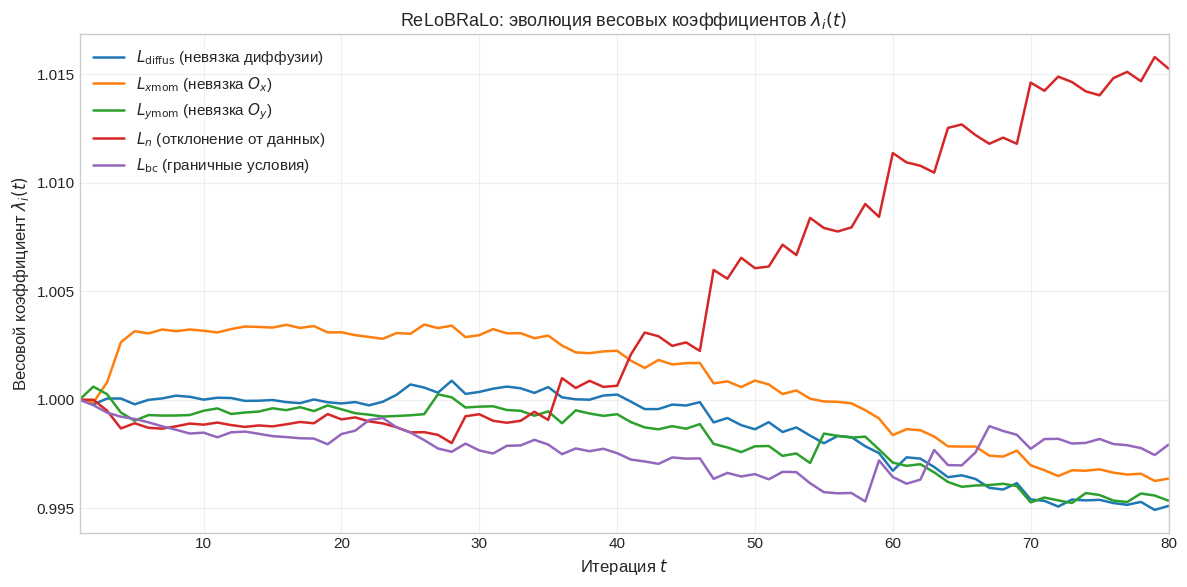

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))
for i, key in enumerate(keys):
    ax.plot(iterations, lambdas[:, i], label=labels[key], linewidth=1.8)

ax.set_xlabel('Итерация $t$')
ax.set_ylabel(r'Весовой коэффициент $\lambda_i(t)$')
ax.set_title(r'ReLoBRaLo: эволюция весовых коэффициентов $\lambda_i(t)$')
ax.legend(loc='best', framealpha=0.95)
ax.set_xlim(1, n_steps)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


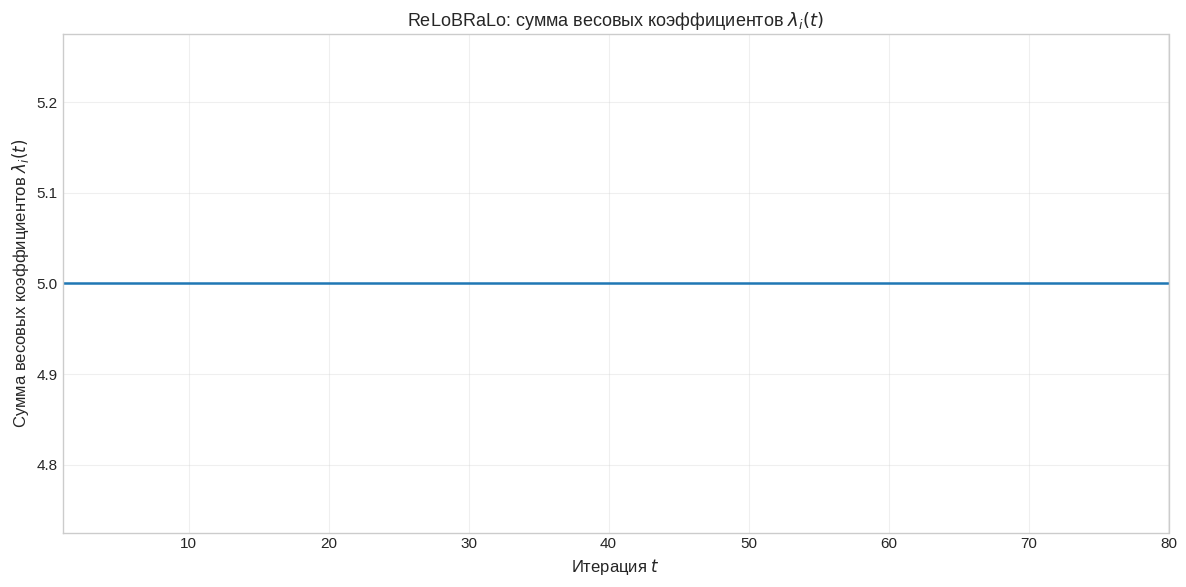

In [5]:
fig, ax = plt.subplots(figsize=(12, 6))
sum_lambdas = lambdas.sum(axis=1)

ax.plot(iterations, sum_lambdas, linewidth=1.8)
ax.set_xlabel('Итерация $t$')
ax.set_ylabel(r'Сумма весовых коэффициентов $\lambda_i(t)$')
ax.set_title(r'ReLoBRaLo: сумма весовых коэффициентов $\lambda_i(t)$')
ax.set_xlim(1, n_steps)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

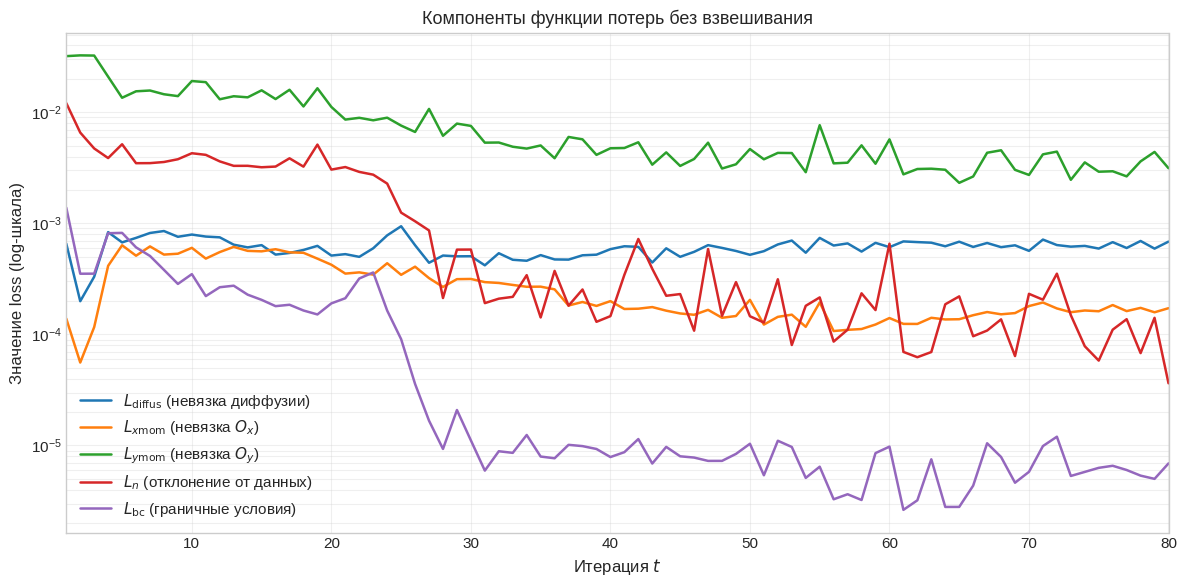

In [6]:
fig, ax = plt.subplots(figsize=(12, 6))
for i, key in enumerate(keys):
    ax.semilogy(iterations, losses[:, i], label=labels[key], linewidth=1.8)

ax.set_xlabel('Итерация $t$')
ax.set_ylabel('Значение loss (log-шкала)')
ax.set_title('Компоненты функции потерь без взвешивания')
ax.legend(loc='best', framealpha=0.95)
ax.set_xlim(1, n_steps)
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()


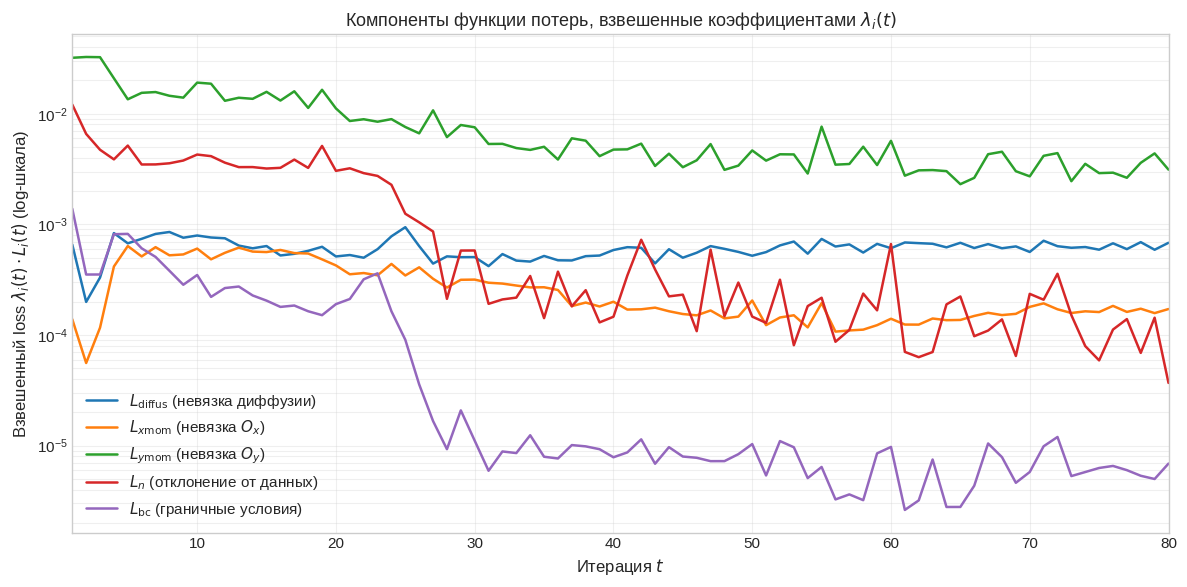

In [7]:
weighted_losses = lambdas * losses

fig, ax = plt.subplots(figsize=(12, 6))
for i, key in enumerate(keys):
    ax.semilogy(iterations, weighted_losses[:, i], label=labels[key], linewidth=1.8)

ax.set_xlabel('Итерация $t$')
ax.set_ylabel(r'Взвешенный loss $\lambda_i(t) \cdot L_i(t)$ (log-шкала)')
ax.set_title(r'Компоненты функции потерь, взвешенные коэффициентами $\lambda_i(t)$')
ax.legend(loc='best', framealpha=0.95)
ax.set_xlim(1, n_steps)
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()


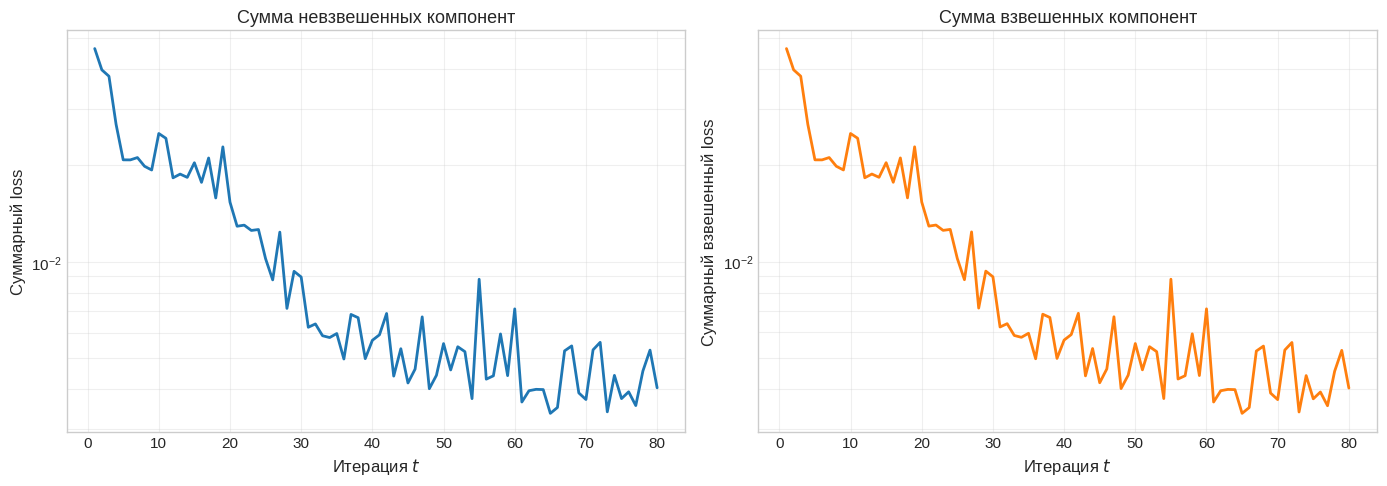

Средний невзвешенный суммарный loss: 1.0362e-02
Средний взвешенный суммарный loss:   1.0354e-02


In [8]:
total_unweighted = losses.sum(axis=1)
total_weighted = weighted_losses.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].semilogy(iterations, total_unweighted, color='C0', linewidth=2)
axes[0].set_xlabel('Итерация $t$')
axes[0].set_ylabel('Суммарный loss')
axes[0].set_title('Сумма невзвешенных компонент')
axes[0].grid(True, which='both', alpha=0.3)

axes[1].semilogy(iterations, total_weighted, color='C1', linewidth=2)
axes[1].set_xlabel('Итерация $t$')
axes[1].set_ylabel('Суммарный взвешенный loss')
axes[1].set_title('Сумма взвешенных компонент')
axes[1].grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

print(f'Средний невзвешенный суммарный loss: {total_unweighted.mean():.4e}')
print(f'Средний взвешенный суммарный loss:   {total_weighted.mean():.4e}')
